# RQ V: Order sensitivity


In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Markdown

repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "reported_runs/analysis").is_dir())
sys.path.insert(0, str(repo)) if str(repo) not in sys.path else None
from reported_runs.analysis.presentation import load_results, NotebookReport, temporal_table, effect_table, rank_summary, unique_trajectories, label_conditions
from reported_runs.analysis.plotting import trajectory_grid, effect_grid, rank_grid, association_grid
from reported_runs.analysis.comparisons import summarise_iterations
%matplotlib inline

results = load_results()
report = NotebookReport(results, 'rq5')
scales = report.scales
trajectory = label_conditions(results["trajectory"])
sources = results["sources"]
summaries = results["summaries"]
effect_summaries = results["effect_summaries"]
pd.set_option("display.max_columns", 18)
pd.set_option("display.max_rows", 60)

## Predictor and outcome


In [2]:
from reported_runs.analysis.sections_rq4_5 import order_plot_wording
order_pairs = results['order_pairs']
order_correlations = results['order_correlations']
report.table(order_pairs, 'rq5_order_sensitivity_pairs', "")

,dataset,study,seed,population_seed,model,stage,window,predictor_metric,predictor_family,baseline_order_sensitivity,head_click_reduction_pp,available
0,movielens,movielens_mitigation_a300_e804,42,1054,agentic_recommender,L3_individual,mean_1_30,agreement_sensitivity,LLM common-valid agreement gap,0.249772,7.93692,True
1,movielens,movielens_mitigation_a300_e804,42,1054,agentic_recommender,L3_individual,iteration_30,agreement_sensitivity,LLM common-valid agreement gap,0.249772,3.26804,True
2,movielens,movielens_mitigation_a300_e804,42,1054,direct_llm,L2_ml_model,mean_1_30,agreement_sensitivity,LLM common-valid agreement gap,0.353267,12.8412,True
3,movielens,movielens_mitigation_a300_e804,42,1054,direct_llm,L2_ml_model,iteration_30,agreement_sensitivity,LLM common-valid agreement gap,0.353267,24.4601,True
4,movielens,movielens_mitigation_a300_e804,42,1054,ncm_inspired_gru_mansoury,L2_ml_model,mean_1_30,shuffle_tvd,Computational probability TVD,0.882039,71.7556,True
5,movielens,movielens_mitigation_a300_e804,42,1054,ncm_inspired_gru_mansoury,L2_ml_model,iteration_30,shuffle_tvd,Computational probability TVD,0.882039,85.6667,True
6,movielens,movielens_mitigation_a300_e804,42,1054,ncm_inspired_gru_uniform,L2_ml_model,mean_1_30,shuffle_tvd,Computational probability TVD,0.670173,33.9556,True
7,movielens,movielens_mitigation_a300_e804,42,1054,ncm_inspired_gru_uniform,L2_ml_model,iteration_30,shuffle_tvd,Computational probability TVD,0.670173,48.3333,True
8,movielens,movielens_mitigation_a300_e804,42,1054,position_biased,L2_ml_model,mean_1_30,shuffle_tvd,Computational probability TVD,0.784146,73.3,True
9,movielens,movielens_mitigation_a300_e804,42,1054,position_biased,L2_ml_model,iteration_30,shuffle_tvd,Computational probability TVD,0.784146,79.6667,True


LaTeX label: `chap:results:tab:rq5_order_sensitivity_pairs` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq5_order_sensitivity_pairs.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq5_order_sensitivity_pairs.csv)

## Exploratory association


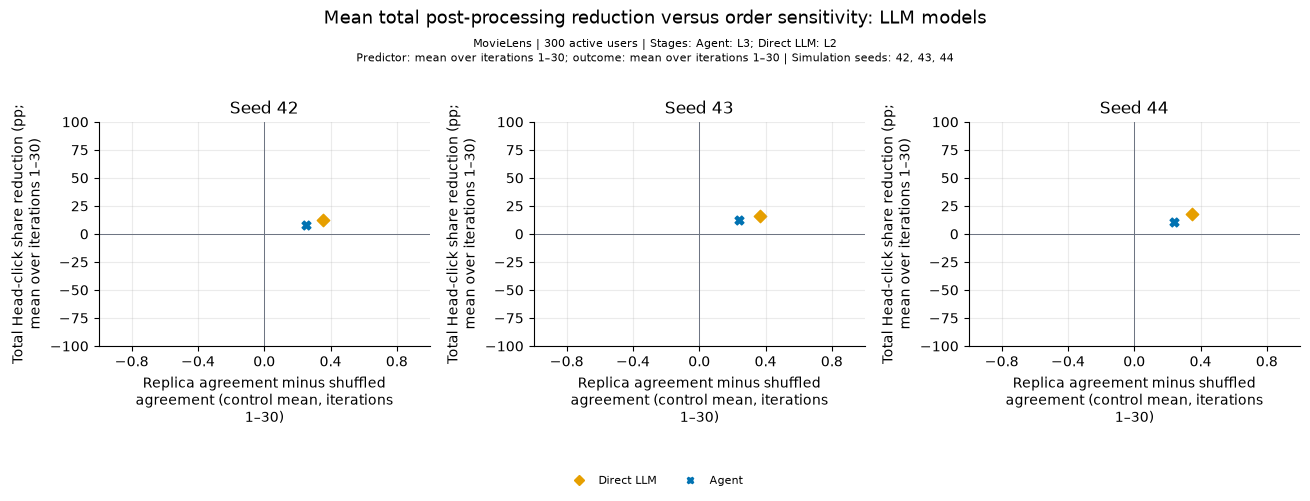

[PDF](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/rq5_llm_sensitivity_association.pdf) · [PNG](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/rq5_llm_sensitivity_association.png) · label `chap:results:fig:rq5_llm_sensitivity_association`

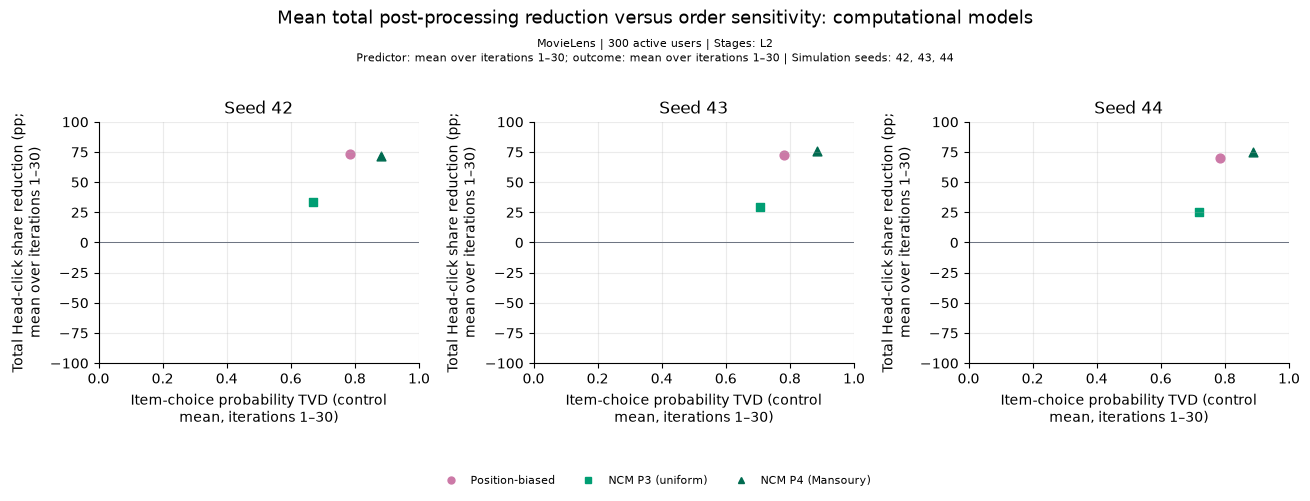

[PDF](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/rq5_computational_sensitivity_association.pdf) · [PNG](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/rq5_computational_sensitivity_association.png) · label `chap:results:fig:rq5_computational_sensitivity_association`

In [3]:
available_pairs = order_pairs[order_pairs['available']]
for family in available_pairs['predictor_family'].unique():
    selected = available_pairs[available_pairs['predictor_family'].eq(family) & available_pairs['window'].eq('mean_1_30')]
    wording = order_plot_wording(family, outcome_window='mean_1_30')
    fig = association_grid(selected, title=wording['title'], x='baseline_order_sensitivity', y='head_click_reduction_pp', x_label=wording['x_label'], y_label=wording['y_label'])
    name = 'computational' if family.startswith('Computational') else 'llm'
    report.figure(fig, selected, f'rq5_{name}_sensitivity_association', "", recommended=False, why="")

In [4]:
report.table(order_correlations, 'rq5_within_seed_associations', "")

,dataset,study,seed,population_seed,window,predictor_family,n_models,spearman_rho,models,interpretation
0,movielens,movielens_mitigation_a300_e804,42,1054,mean_1_30,LLM common-valid agreement gap,2,—,agentic_recommender; direct_llm,"Descriptive only; separate predictor families,..."
1,movielens,movielens_mitigation_a300_e804,42,1054,iteration_30,LLM common-valid agreement gap,2,—,agentic_recommender; direct_llm,"Descriptive only; separate predictor families,..."
2,movielens,movielens_mitigation_a300_e804,42,1054,mean_1_30,Computational probability TVD,3,0.5,ncm_inspired_gru_mansoury; ncm_inspired_gru_un...,"Descriptive only; separate predictor families,..."
3,movielens,movielens_mitigation_a300_e804,42,1054,iteration_30,Computational probability TVD,3,1,ncm_inspired_gru_mansoury; ncm_inspired_gru_un...,"Descriptive only; separate predictor families,..."
4,movielens,movielens_mitigation_a300_e804,43,19277,mean_1_30,LLM common-valid agreement gap,2,—,agentic_recommender; direct_llm,"Descriptive only; separate predictor families,..."
5,movielens,movielens_mitigation_a300_e804,43,19277,iteration_30,LLM common-valid agreement gap,2,—,agentic_recommender; direct_llm,"Descriptive only; separate predictor families,..."
6,movielens,movielens_mitigation_a300_e804,43,19277,mean_1_30,Computational probability TVD,3,1,ncm_inspired_gru_mansoury; ncm_inspired_gru_un...,"Descriptive only; separate predictor families,..."
7,movielens,movielens_mitigation_a300_e804,43,19277,iteration_30,Computational probability TVD,3,0.5,ncm_inspired_gru_mansoury; ncm_inspired_gru_un...,"Descriptive only; separate predictor families,..."
8,movielens,movielens_mitigation_a300_e804,44,18844,mean_1_30,LLM common-valid agreement gap,2,—,agentic_recommender; direct_llm,"Descriptive only; separate predictor families,..."
9,movielens,movielens_mitigation_a300_e804,44,18844,iteration_30,LLM common-valid agreement gap,2,—,agentic_recommender; direct_llm,"Descriptive only; separate predictor families,..."


LaTeX label: `chap:results:tab:rq5_within_seed_associations` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq5_within_seed_associations.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq5_within_seed_associations.csv)

## Replica agreement and shuffling eligibility


In [5]:
control_ids = sources[sources['study'].eq('movielens_mitigation_a300_e804') & sources['intervention'].eq('control')][['study', 'condition_id', 'seed']]
baseline_probes = results['probes'].merge(control_ids, on=['study', 'condition_id', 'seed'], validate='many_to_one')
probe_summary = summarise_iterations(baseline_probes, [m for m in ['replica_agreement', 'shuffled_agreement', 'agreement_sensitivity', 'replica_pair_agreement', 'shuffle_tvd', 'triple_valid_clicks', 'tvd_opportunities'] if m in baseline_probes])
report.table(temporal_table(probe_summary, probe_summary['metric'].unique().tolist()), 'rq5_predictor_eligibility', "")

,dataset,study,model,condition_id,seed,window,Replica agreement minus shuffled agreement,Same-item replica agreement,Same-item replica agreement (both click),Item-choice probability TVD,Same-item shuffled agreement,Triple valid clicks,Tvd opportunities
0,movielens,movielens_mitigation_a300_e804,agentic_recommender,agentic_recommender__control,42,iteration_30,0.283898,0.614407,0.612,—,0.330508,236,0
1,movielens,movielens_mitigation_a300_e804,agentic_recommender,agentic_recommender__control,42,mean_1_30,0.249772,0.624193,0.623542,—,0.374421,255.333,0
2,movielens,movielens_mitigation_a300_e804,agentic_recommender,agentic_recommender__control,43,iteration_30,0.252964,0.557312,0.56705,—,0.304348,253,0
3,movielens,movielens_mitigation_a300_e804,agentic_recommender,agentic_recommender__control,43,mean_1_30,0.23724,0.618781,0.618096,—,0.381542,252.067,0
4,movielens,movielens_mitigation_a300_e804,agentic_recommender,agentic_recommender__control,44,iteration_30,0.268199,0.601533,0.593407,—,0.333333,261,0
5,movielens,movielens_mitigation_a300_e804,agentic_recommender,agentic_recommender__control,44,mean_1_30,0.240853,0.635979,0.63531,—,0.395126,258.233,0
6,movielens,movielens_mitigation_a300_e804,direct_llm,direct_llm__control,42,iteration_30,0.46281,0.702479,0.707792,—,0.239669,121,0
7,movielens,movielens_mitigation_a300_e804,direct_llm,direct_llm__control,42,mean_1_30,0.353267,0.614312,0.610036,—,0.261045,82.3,0
8,movielens,movielens_mitigation_a300_e804,direct_llm,direct_llm__control,43,iteration_30,0.512,0.672,0.662577,—,0.16,125,0
9,movielens,movielens_mitigation_a300_e804,direct_llm,direct_llm__control,43,mean_1_30,0.36913,0.651562,0.650849,—,0.282433,86.5,0


LaTeX label: `chap:results:tab:rq5_predictor_eligibility` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq5_predictor_eligibility.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/rq5_predictor_eligibility.csv)

## Endpoint companion


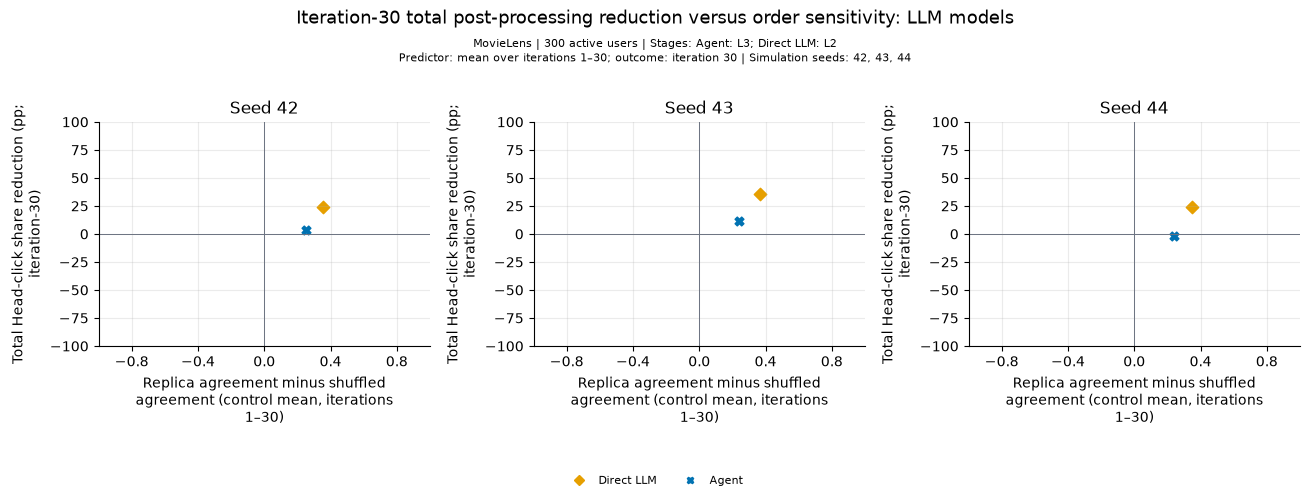

[PDF](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/rq5_llm_endpoint_association.pdf) · [PNG](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/rq5_llm_endpoint_association.png) · label `chap:results:fig:rq5_llm_endpoint_association`

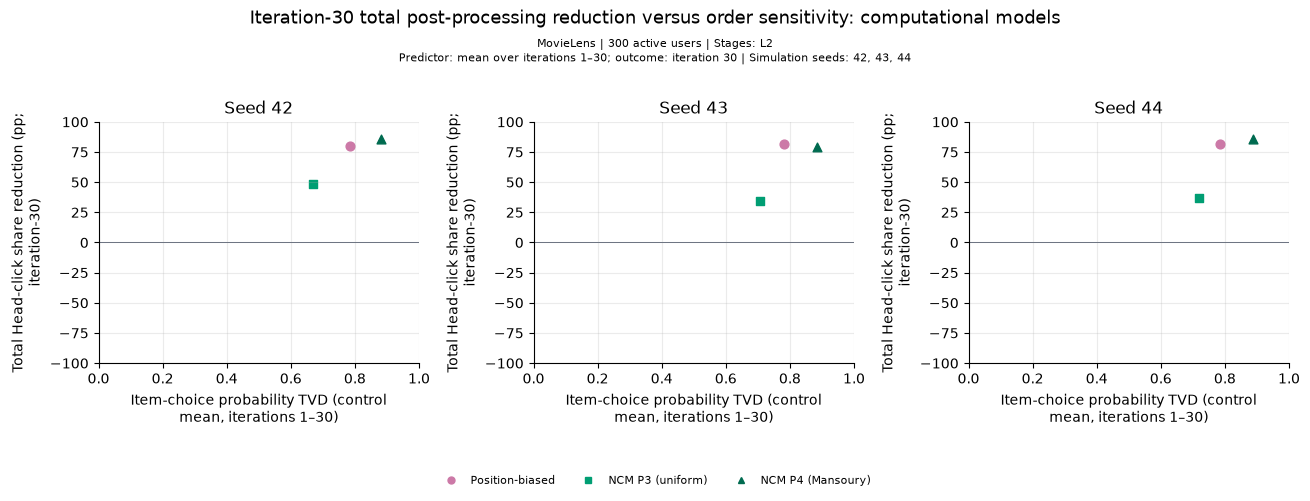

[PDF](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/rq5_computational_endpoint_association.pdf) · [PNG](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/rq5_computational_endpoint_association.png) · label `chap:results:fig:rq5_computational_endpoint_association`

In [6]:
endpoint_pairs = available_pairs[available_pairs['window'].eq('iteration_30')]
for family in endpoint_pairs['predictor_family'].unique():
    selected = endpoint_pairs[endpoint_pairs['predictor_family'].eq(family)]
    wording = order_plot_wording(family, outcome_window='iteration_30')
    fig = association_grid(selected, title=wording['title'], x='baseline_order_sensitivity', y='head_click_reduction_pp', x_label=wording['x_label'], y_label=wording['y_label'])
    name = 'computational' if family.startswith('Computational') else 'llm'
    report.figure(fig, selected, f'rq5_{name}_endpoint_association', "")